In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score,mean_absolute_percentage_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
data1=fetch_california_housing()
X=data1.data
Y=data1.target
feature_names=data1.feature_names
print(feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [9]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=42)

In [21]:
lambdas=np.logspace(-3,5,50)
ridge_coefs=[]
rmse_vals=[]
for alpha in lambdas:
    ridge=Ridge(alpha=alpha)
    ridge.fit(X_train,Y_train)
    ridge_coefs.append(ridge.coef_)
    Y_pred=ridge.predict(X_test)
    rmse_vals.append(np.sqrt(mean_squared_error(Y_test,Y_pred)))
ridge_coefs=np.array(ridge_coefs)   
ridge_coefs    

array([[ 4.45822383e-01,  9.68187003e-03, -1.22094764e-01,
         7.78597623e-01, -7.75735110e-07, -3.37002613e-03,
        -4.18536740e-01, -4.33687944e-01],
       [ 4.45822299e-01,  9.68187096e-03, -1.22094606e-01,
         7.78596741e-01, -7.75732696e-07, -3.37002589e-03,
        -4.18536736e-01, -4.33687930e-01],
       [ 4.45822178e-01,  9.68187231e-03, -1.22094375e-01,
         7.78595455e-01, -7.75729180e-07, -3.37002553e-03,
        -4.18536732e-01, -4.33687909e-01],
       [ 4.45822001e-01,  9.68187429e-03, -1.22094039e-01,
         7.78593583e-01, -7.75724059e-07, -3.37002501e-03,
        -4.18536725e-01, -4.33687878e-01],
       [ 4.45821743e-01,  9.68187716e-03, -1.22093549e-01,
         7.78590858e-01, -7.75716602e-07, -3.37002426e-03,
        -4.18536715e-01, -4.33687834e-01],
       [ 4.45821368e-01,  9.68188135e-03, -1.22092836e-01,
         7.78586888e-01, -7.75705742e-07, -3.37002315e-03,
        -4.18536701e-01, -4.33687769e-01],
       [ 4.45820822e-01,  9.681887

In [22]:
# Convert coefficients to DataFrame
ridge_df = pd.DataFrame(ridge_coefs, columns=feature_names)
ridge_df.insert(0, "Lambda", lambdas)  # Add lambda column at the front

# Optionally view the first few rows of coefficients
print(ridge_df.shape)
print(ridge_df.head())

(50, 9)
     Lambda    MedInc  HouseAge  AveRooms  AveBedrms    Population  AveOccup  \
0  0.001000  0.445822  0.009682 -0.122095   0.778598 -7.757351e-07  -0.00337   
1  0.001456  0.445822  0.009682 -0.122095   0.778597 -7.757327e-07  -0.00337   
2  0.002121  0.445822  0.009682 -0.122094   0.778595 -7.757292e-07  -0.00337   
3  0.003089  0.445822  0.009682 -0.122094   0.778594 -7.757241e-07  -0.00337   
4  0.004498  0.445822  0.009682 -0.122094   0.778591 -7.757166e-07  -0.00337   

   Latitude  Longitude  
0 -0.418537  -0.433688  
1 -0.418537  -0.433688  
2 -0.418537  -0.433688  
3 -0.418537  -0.433688  
4 -0.418537  -0.433688  


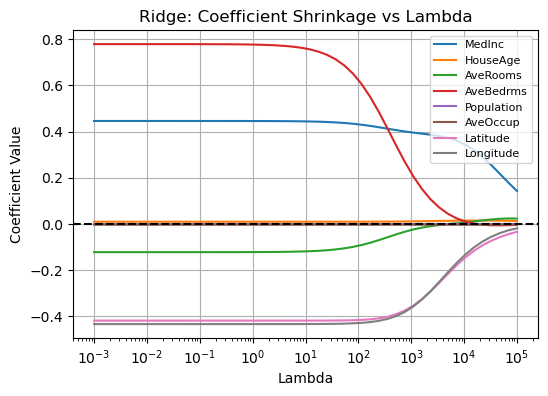

In [23]:
plt.figure(figsize=(6, 4))
for i in range(X.shape[1]):
    plt.plot(lambdas, ridge_coefs[:, i], label=feature_names[i])
plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Coefficient Value")
plt.title("Ridge: Coefficient Shrinkage vs Lambda")
plt.axhline(0, color="black", linestyle="--")
plt.legend(loc="best", fontsize=8)
plt.grid(True)
plt.show()